<a href="https://colab.research.google.com/github/Rodriguez-9819/Aaron_INFO4670_Fall2026/blob/main/INFO4670_Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Student:** Aaron Rodriguez  
**Submission:** Assignment 5

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [ ]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> A false positive is more costly when the carrier automatically blocks a message. A legitimate message could contain an appointment reminder, an emergency update, or a login code that the user needs. A false negative lets spam reach the user and could lead to a phishing scam or financial loss. Both errors matter, but I would first limit the number of legitimate messages blocked.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> **Precision** should be the primary target. Spam is the positive class, so precision measures how many messages flagged as spam really are spam: TP / (TP + FP). Higher precision means fewer legitimate messages among the blocked messages. I would still report recall and F1 because a filter that misses most spam would not be useful, even with high precision.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> Using the rounded 13% spam rate, an always-ham model would achieve about **87% accuracy**. The exact dataset baseline is 4,825 / 5,572 = **86.59%**. This is misleading because the model catches no spam: spam recall and spam F1 are both zero. Most messages are legitimate, so accuracy alone rewards always choosing the majority class.

---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [ ]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


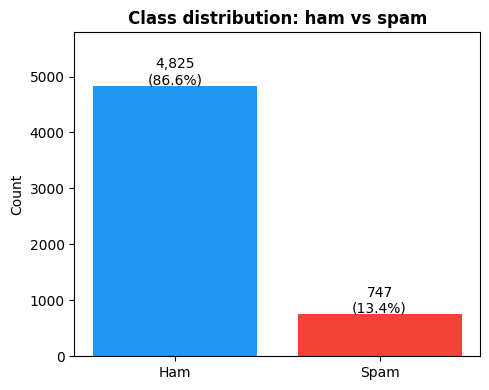

In [ ]:
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_ylim(0, max(ham_count, spam_count) * 1.20)
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [ ]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


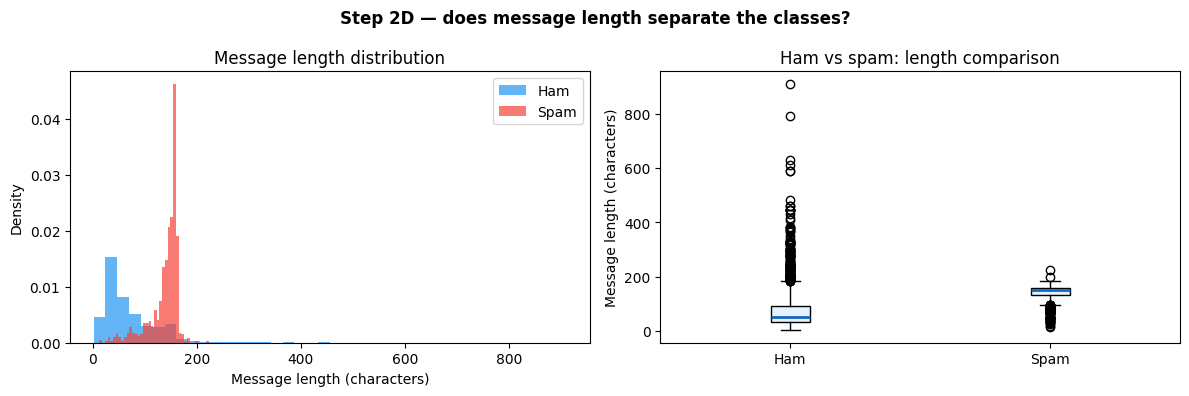

In [ ]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [ ]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [ ]:
def build_features_v2(df):
    d = build_features(df)  # retain the four supplied starter features
    msg = d['message'].str.lower()

    # Feature 5: links beginning with http://, https://, or www.
    d['has_url'] = msg.str.contains(
        r'https?://\S+|www\.\S+', regex=True, na=False
    ).astype(int)

    # Feature 6: requests to interact by text or reply.
    d['has_reply_request'] = msg.str.contains(
        r'\b(?:txt|text|reply)\b', regex=True, na=False
    ).astype(int)
    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

assert len(feature_cols) == 6
assert df[feature_cols].isin([0, 1]).all().all()

print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df.loc[df['spam'] == 1, feat].mean()
    ha = df.loc[df['spam'] == 0, feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

feature_rates = df.groupby('spam')[feature_cols].mean().T
feature_rates.columns = ['Ham', 'Spam']
feature_gaps = (feature_rates['Spam'] - feature_rates['Ham']).sort_values(ascending=False)
print(f'\nLargest spam-minus-ham gap: {feature_gaps.index[0]} '
      f'({feature_gaps.iloc[0]:.2%})')

All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                14.2%    0.0%  +14.1%
has_reply_request      40.7%    2.5%  +38.2%

Largest spam-minus-ham gap: is_long (62.69%)


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


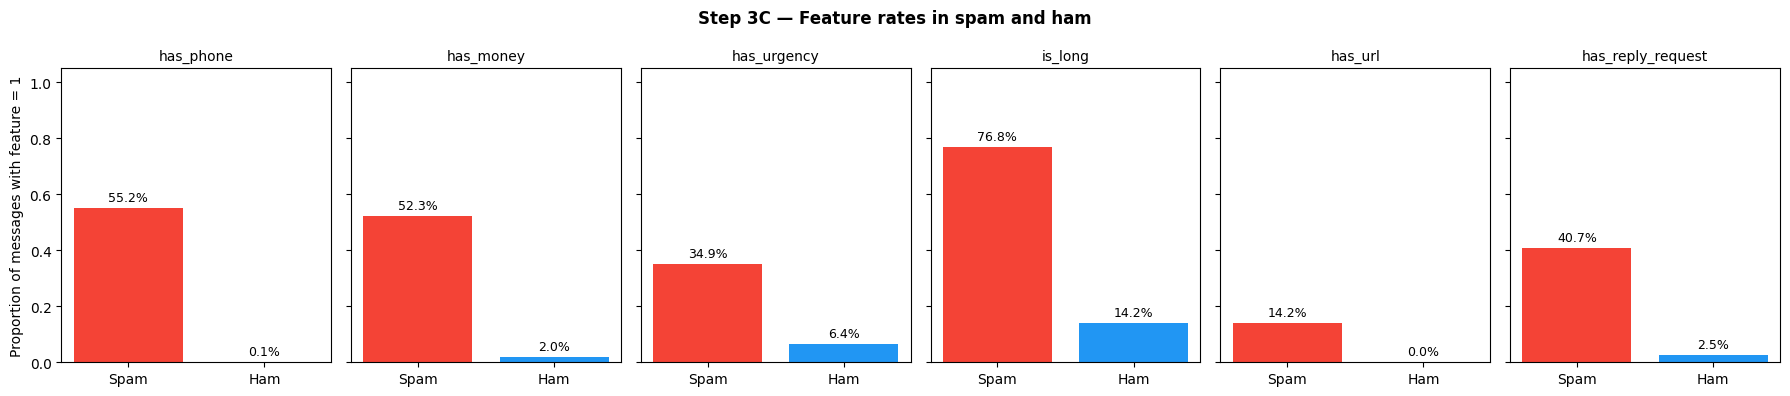

In [ ]:
n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(3 * n_features, 4), sharey=True)
for ax, feat in zip(np.atleast_1d(axes), feature_cols):
    rates = [df.loc[df['spam'] == 1, feat].mean(),
             df.loc[df['spam'] == 0, feat].mean()]
    bars = ax.bar(['Spam', 'Ham'], rates, color=['#F44336', '#2196F3'])
    ax.set_title(feat, fontsize=10)
    ax.set_ylim(0, 1.05)
    for bar, rate in zip(bars, rates):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.025,
                f'{rate:.1%}', ha='center', fontsize=9)
axes[0].set_ylabel('Proportion of messages with feature = 1')
fig.suptitle('Step 3C — Feature rates in spam and ham', fontweight='bold')
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> **`has_url`** is 1 if the message contains a link beginning with `http://`, `https://`, or `www.`; otherwise it is 0. Links can lead users to a phishing page or a promotion, so this adds a signal that the starter features do not directly check. It carries over the idea of checking suspicious links from the fraud-email discussion, although a URL alone does not prove fraud.

*Feature 2 — name and explanation:*
> **`has_reply_request`** is 1 if the message contains the whole word `txt`, `text`, or `reply`, ignoring capitalization. Spam often asks the recipient to respond to enter a contest, claim an offer, or contact a paid service. This captures a request to interact rather than a phone number, money word, urgency word, or message-length threshold.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> **`is_long` has the largest gap:** it is present in 76.84% of spam and 14.16% of ham, a difference of **62.69 percentage points**. A large gap means the feature can separate the classes and make the child nodes purer. In the lecture, Information Gain is the parent entropy minus the weighted child entropies; better separation can produce a larger gain. The required scikit-learn tree uses its default **Gini impurity**, so its actual split criterion is weighted Gini reduction, not entropy. A large raw gap does not guarantee the root because class balance and weighting also matter, but the trained tree did choose `is_long` as its root.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> The second spam example in Step 2C starts with **“FreeMsg Hey there darling”**. `has_money` is 0 because `FreeMsg` is not the separate word `free`, and the supplied money pattern does not recognize its pound-denominated charge. `has_phone`, `has_url`, and `has_reply_request` are also 0 because the text has no matching phone number, URL, or whole-word `txt`, `text`, or `reply`. Only `has_urgency` and `is_long` are 1. These general signals are not sufficient: both fitted models classify this example as ham, illustrating a missed spam message. The features also miss the short, login-code phishing example printed in Step 6A.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [ ]:
X = df[feature_cols].values
y = df['spam'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f'Training set: {len(y_train):,} messages ({y_train.mean():.2%} spam)')
print(f'Test set:     {len(y_test):,} messages ({y_test.mean():.2%} spam)')
print(f'Features: {feature_cols}')
print('Only text-derived binary features enter X; the label is used only as y.')

# Audit repeated messages without changing the instructor-required split.
all_positions = np.arange(len(df))
train_positions, test_positions = train_test_split(
    all_positions, test_size=0.25, random_state=42, stratify=y
)
duplicate_count = df.duplicated(subset=['label', 'message']).sum()
overlap_count = len(set(df.iloc[train_positions]['message']) &
                    set(df.iloc[test_positions]['message']))
print(f'Exact duplicate labeled rows: {duplicate_count:,}')
print(f'Distinct message texts appearing in both splits: {overlap_count:,}')
print('Repeated texts can inflate estimated performance; a production evaluation '
      'should also use deduplicated or group-separated messages.')

Training set: 4,179 messages (13.40% spam)
Test set:     1,393 messages (13.42% spam)
Features: ['has_phone', 'has_money', 'has_urgency', 'is_long', 'has_url', 'has_reply_request']
Only text-derived binary features enter X; the label is used only as y.
Exact duplicate labeled rows: 403
Distinct message texts appearing in both splits: 131
Repeated texts can inflate estimated performance; a production evaluation should also use deduplicated or group-separated messages.


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> `stratify=y` keeps the spam/ham proportions close to the full dataset in both sets. This matters because spam is the minority class. Without stratification, one split could contain too few spam messages, making recall and precision less stable and the test set less representative.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would prefer stratified k-fold cross-validation when comparing models on a small, imbalanced dataset, where one lucky train/test split could change the apparent winner. Each training example is used for validation once, so the mean and variation across folds give a more reliable comparison. Cross-validation should be performed on the training data, leaving the final test set separate. It does not solve duplicate-message overlap by itself; duplicate groups should also be kept together in a production evaluation.

---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 14
Root feature: is_long
Decision Tree rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_request <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_request >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_request <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_request >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   | 

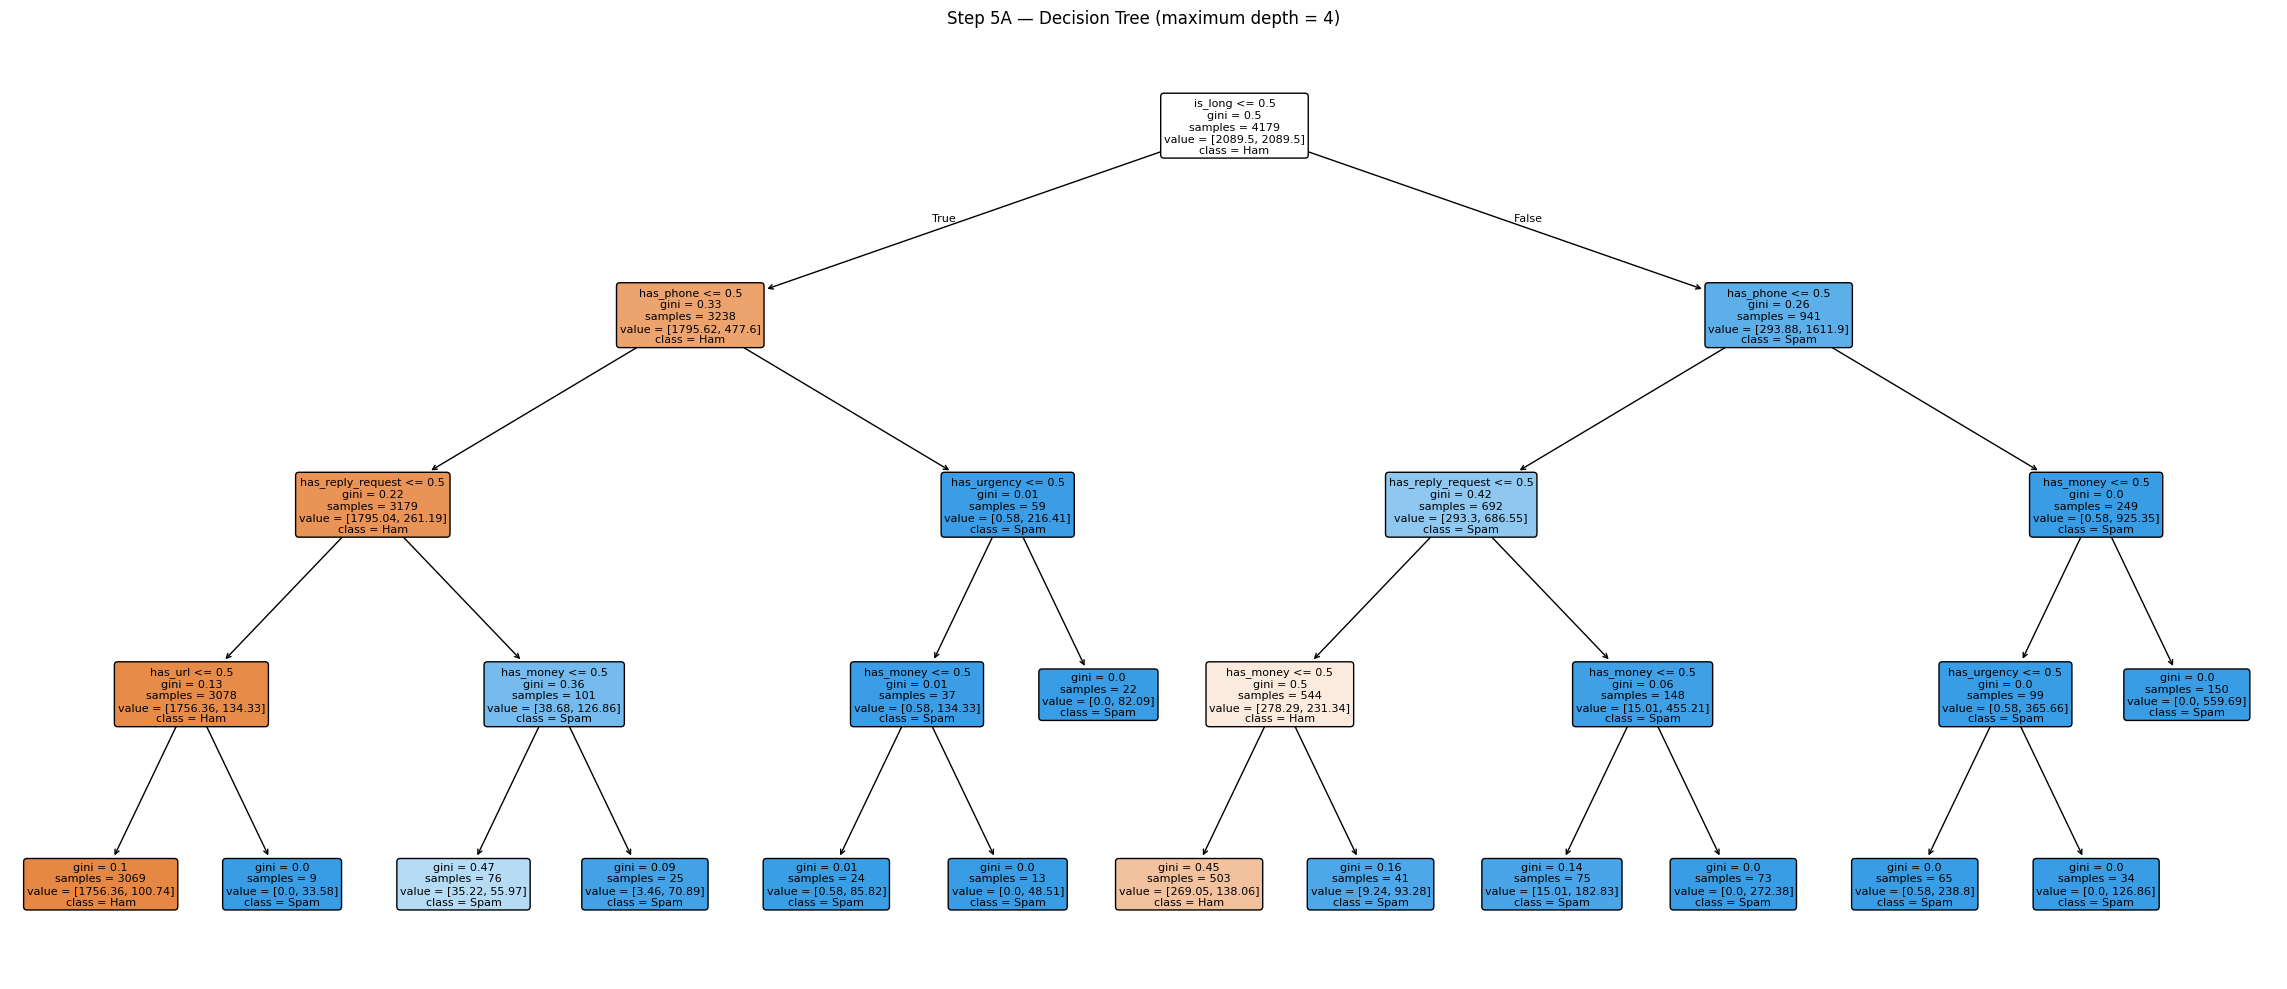

In [ ]:
dt_model = DecisionTreeClassifier(
    max_depth=4, random_state=42, class_weight='balanced'
)
dt_model.fit(X_train, y_train)
print(f'Number of leaves: {dt_model.get_n_leaves()}')
print(f'Root feature: {feature_cols[dt_model.tree_.feature[0]]}')
plt.figure(figsize=(23, 10))
plot_tree(dt_model, feature_names=feature_cols,
          class_names=['Ham', 'Spam'], filled=True, rounded=True,
          fontsize=8, precision=2)
plt.title('Step 5A — Decision Tree (maximum depth = 4)')
plt.tight_layout()
plt.show()
print('Decision Tree rules:')
print(export_text(dt_model, feature_names=feature_cols))

### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


is_long              0.517271
has_phone            0.236019
has_reply_request    0.170684
has_money            0.039595
has_url              0.036429
has_urgency          0.000002
Actual root feature: is_long
Importance sums contributions across all splits; the most important feature is not necessarily the root in every tree.


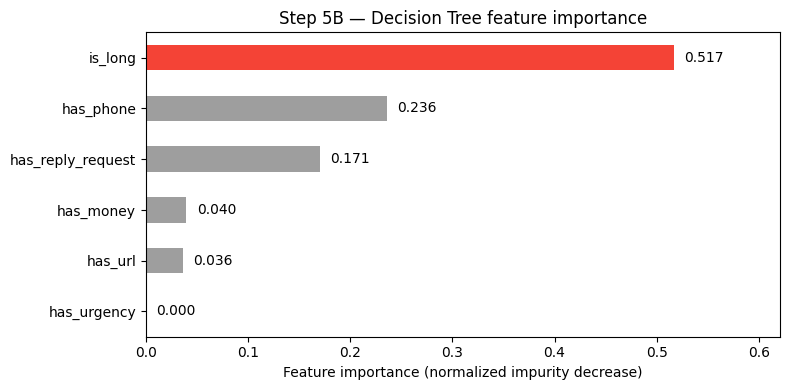

In [ ]:
importances = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values()
colors = ['#F44336' if feature == importances.idxmax() else '#9E9E9E'
          for feature in importances.index]
ax = importances.plot(kind='barh', color=colors, figsize=(8, 4))
ax.set_xlabel('Feature importance (normalized impurity decrease)')
ax.set_title('Step 5B — Decision Tree feature importance')
ax.set_xlim(0, max(importances.max() * 1.2, 0.1))
for position, value in enumerate(importances):
    ax.text(value + 0.01, position, f'{value:.3f}', va='center')
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).to_string())
print(f'Actual root feature: {feature_cols[dt_model.tree_.feature[0]]}')
print('Importance sums contributions across all splits; the most important '
      'feature is not necessarily the root in every tree.')

### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


Depth  Train F1  Test F1  Train - Test F1
    1    0.5756   0.5646           0.0110
    2    0.6282   0.6210           0.0073
    3    0.8272   0.8347          -0.0075
    4    0.8500   0.8527          -0.0027
    5    0.8617   0.8615           0.0002
    6    0.8591   0.8593          -0.0003
 None    0.8591   0.8593          -0.0003
No clear positive train/test F1 gap widening of more than 0.005 appears across these depths.
Small fluctuations alone are not proof of overfitting. The limited binary features also restrict how complex the tree can become.
This is the required depth diagnostic; the comparison model remains the specified depth-4 tree. Test scores are not used to tune it.


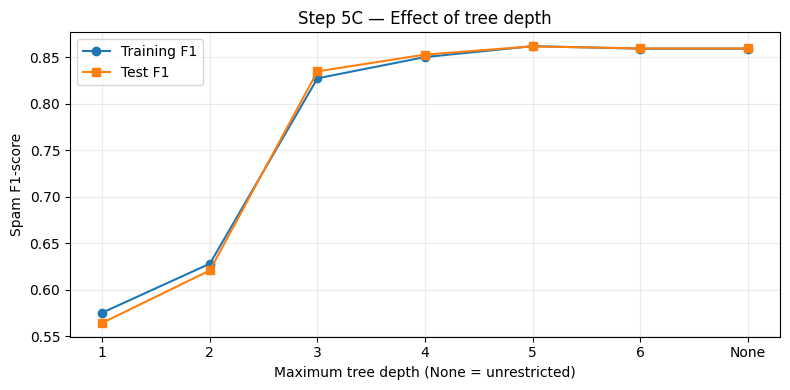

In [ ]:
depths = [1, 2, 3, 4, 5, 6, None]
depth_records = []
for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth, random_state=42, class_weight='balanced'
    )
    model.fit(X_train, y_train)
    depth_records.append({
        'Depth': 'None' if depth is None else str(depth),
        'Train F1': f1_score(y_train, model.predict(X_train), zero_division=0),
        'Test F1': f1_score(y_test, model.predict(X_test), zero_division=0)
    })
depth_results = pd.DataFrame(depth_records)
depth_results['Train - Test F1'] = depth_results['Train F1'] - depth_results['Test F1']
print(depth_results.to_string(index=False, float_format=lambda value: f'{value:.4f}'))

positions = np.arange(len(depths))
plt.figure(figsize=(8, 4))
plt.plot(positions, depth_results['Train F1'], marker='o', label='Training F1')
plt.plot(positions, depth_results['Test F1'], marker='s', label='Test F1')
plt.xticks(positions, depth_results['Depth'])
plt.xlabel('Maximum tree depth (None = unrestricted)')
plt.ylabel('Spam F1-score')
plt.title('Step 5C — Effect of tree depth')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

gaps = depth_results['Train - Test F1']
widening = [i for i in range(1, len(gaps)) if gaps.iloc[i] > 0 and
            gaps.iloc[i] > max(gaps.iloc[i - 1], 0) + 0.005]
if widening:
    i = widening[0]
    print(f'The first widening of the positive train/test F1 gap by more than '
          f'0.005 occurs at depth {depth_results.iloc[i]["Depth"]}.')
else:
    print('No clear positive train/test F1 gap widening of more than 0.005 '
          'appears across these depths.')
print('Small fluctuations alone are not proof of overfitting. The limited '
      'binary features also restrict how complex the tree can become.')
print('This is the required depth diagnostic; the comparison model remains '
      'the specified depth-4 tree. Test scores are not used to tune it.')

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [ ]:
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)
print('Bernoulli Naive Bayes trained on the same six binary features.')
print(f'Training class counts [Ham, Spam]: {nb_model.class_count_.astype(int)}')

Bernoulli Naive Bayes trained on the same six binary features.
Training class counts [Ham, Spam]: [3619  560]


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


Spam is the positive class (1). Rows = actual; columns = predicted.
Decision Tree: TP=165, FP=35, FN=22, TN=1171
Naive Bayes: TP=161, FP=21, FN=26, TN=1185

Hypothetical phishing example: Could you send the login code you received to finish the update?
Feature values: {'has_phone': 0, 'has_money': 0, 'has_urgency': 0, 'is_long': 0, 'has_url': 0, 'has_reply_request': 0}
Predictions: {'Decision Tree': 0, 'Naive Bayes': 0} (0 = Ham, 1 = Spam)


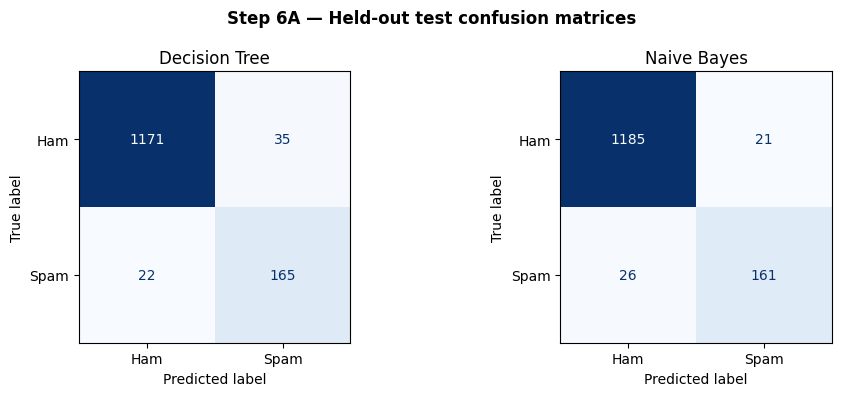

In [ ]:
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)
prediction_sets = {'Decision Tree': y_pred_dt, 'Naive Bayes': y_pred_nb}
confusion_counts = {}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, predictions) in zip(axes, prediction_sets.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['Ham', 'Spam']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    confusion_counts[name] = {'TP': int(tp), 'FP': int(fp),
                              'FN': int(fn), 'TN': int(tn)}
plt.suptitle('Step 6A — Held-out test confusion matrices', fontweight='bold')
plt.tight_layout()
plt.show()

print('Spam is the positive class (1). Rows = actual; columns = predicted.')
for name, counts in confusion_counts.items():
    print(f'{name}: TP={counts["TP"]}, FP={counts["FP"]}, '
          f'FN={counts["FN"]}, TN={counts["TN"]}')

# A hypothetical phishing message, kept separate from the real dataset.
evasive_message = 'Could you send the login code you received to finish the update?'
evasive_features = build_features_v2(pd.DataFrame({'message': [evasive_message]}))
evasive_X = evasive_features[feature_cols].values
print('\nHypothetical phishing example:', evasive_message)
print('Feature values:', evasive_features[feature_cols].iloc[0].to_dict())
print('Predictions:', {'Decision Tree': int(dt_model.predict(evasive_X)[0]),
                        'Naive Bayes': int(nb_model.predict(evasive_X)[0])},
      '(0 = Ham, 1 = Spam)')

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree    0.9591     0.8250  0.8824    0.8527
  Naive Bayes    0.9663     0.8846  0.8610    0.8726
Primary evaluation target chosen in Q1b: spam precision.


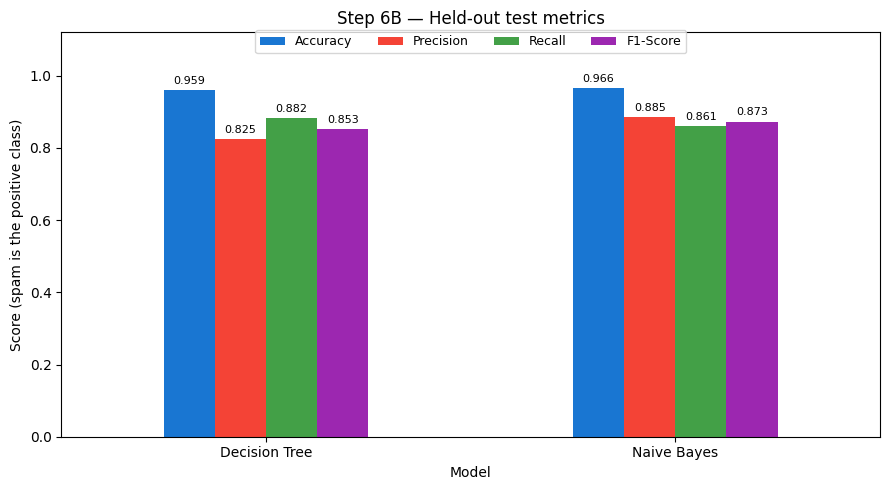

In [ ]:
metric_records = []
for name, predictions in prediction_sets.items():
    metric_records.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0)
    })
metrics_comparison = pd.DataFrame(metric_records)
print(metrics_comparison.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print('Primary evaluation target chosen in Q1b: spam precision.')

ax = metrics_comparison.set_index('Model').plot(
    kind='bar', figsize=(9, 5), rot=0,
    color=['#1976D2', '#F44336', '#43A047', '#9C27B0']
)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score (spam is the positive class)')
ax.set_title('Step 6B — Held-out test metrics')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8)
plt.tight_layout()
plt.show()

### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
print('Five-fold stratified cross-validation on the TRAINING set only.')
print('F1 is required by the rubric; precision also checks the Q1b target.')
for name, model in [('Decision Tree', dt_model), ('Naive Bayes', nb_model)]:
    f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    precision_scores = cross_val_score(model, X_train, y_train, cv=cv,
                                       scoring='precision')
    cv_results[name] = {'f1': f1_scores.tolist(),
                        'precision': precision_scores.tolist()}
    print(f'\n{name}')
    print(f'  F1 by fold: {np.round(f1_scores, 4)}')
    print(f'  Mean F1: {f1_scores.mean():.4f} '
          f'(standard deviation {f1_scores.std():.4f})')
    print(f'  Precision by fold: {np.round(precision_scores, 4)}')
    print(f'  Mean precision: {precision_scores.mean():.4f} '
          f'(standard deviation {precision_scores.std():.4f})')
print('The final test set is not included in cross-validation. Duplicate '
      'messages remain a limitation of this required row-level workflow.')

Five-fold stratified cross-validation on the TRAINING set only.
F1 is required by the rubric; precision also checks the Q1b target.

Decision Tree
  F1 by fold: [0.8509 0.8412 0.8783 0.834  0.8465]
  Mean F1: 0.8502 (standard deviation 0.0151)
  Precision by fold: [0.8362 0.8099 0.8559 0.7967 0.7907]
  Mean precision: 0.8179 (standard deviation 0.0246)

Naive Bayes
  F1 by fold: [0.8716 0.8739 0.9182 0.8796 0.886 ]
  Mean F1: 0.8858 (standard deviation 0.0169)
  Precision by fold: [0.8962 0.8818 0.9352 0.9135 0.8707]
  Mean precision: 0.8995 (standard deviation 0.0229)
The final test set is not included in cross-validation. Duplicate messages remain a limitation of this required row-level workflow.


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> The Decision Tree correctly catches **165 spam messages (TP)**, misses **22 spam messages (FN)**, and wrongly blocks **35 legitimate messages (FP)**. It correctly allows 1,171 legitimate messages (TN).

*Naive Bayes:*
> Naive Bayes correctly catches **161 spam messages (TP)**, misses **26 spam messages (FN)**, and wrongly blocks **21 legitimate messages (FP)**. It correctly allows 1,185 legitimate messages (TN).

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> **Naive Bayes wins on precision**, my primary metric from Q1b: **88.46%** versus **82.50%** for the Decision Tree, an advantage of **5.96 percentage points**. Cross-validation supports the same ordering: average precision is 89.95% for Naive Bayes and 81.79% for the tree. The rubric-required average F1 also favors Naive Bayes, 0.8858 versus 0.8502. F1 alone would not directly confirm a precision-based decision, which is why Step 6C also reports precision. These are estimates rather than proof of future performance; 131 distinct message texts appear in both the required train/test splits.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I recommend **Bernoulli Naive Bayes** as the starting model because precision is the main priority for automatically blocking messages. Its test precision is **88.46%**, and it wrongly blocks **21 legitimate messages**, compared with 35 for the Decision Tree. Its weakness is that it misses **26 spam messages**, four more than the tree, so some harmful messages would still reach users. I would improve the features by detecting account-verification and login-code requests, then retrain on recent labeled SMS messages. Before deployment, I would validate it on a fresh, deduplicated test set and route uncertain messages to a reviewable spam folder.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> **`has_url`:** this feature only checks for a web prefix, so a legitimate-looking phishing URL and a genuine business link receive the same value; it cannot judge whether the destination is trustworthy. It also misses a bare domain without `http://`, `https://`, or `www.`, so some modern phishing links would not trigger it. **`has_reply_request`:** this feature only recognizes `txt`, `text`, and `reply`. A professional-looking scam such as “Please review your account security settings” can request action without using any of those exact words, leaving the feature at 0. Both features would need broader context and testing on newer messages.
